# 17 — Técnicas de la clase de preprocesamiento aplicadas a la ampliación
La guía de la clase (`guia/guia_clase_preprocesamiento.md`, secciones 3 y 8.2) deja varias técnicas que el proyecto todavía no mostraba. Este
notebook aplica las que **sí tienen sentido en un análisis descriptivo sin variable objetivo**, sobre la capa curada de los 1.655 procesos no
penales y sobre la serie 2007-2023 del notebook 15:

| Tema de la clase | Qué se hace aquí |
|---|---|
| 3.3 Outliers: asimetría antes y después de `log1p` y winsorización | `scipy.stats.skew` de cada indicador, con la tabla de interpretación de la clase |
| 3.6 Discretización: `pd.cut` y `pd.qcut` | bandas del CEJA y terciles de duración, cruzados con la materia |
| 3.8 Feature engineering: agrupaciones y variables temporales | `groupby().transform`, `merge(..., suffixes=...)`, `shift`, `pct_change`, `rolling` |
| 3.10 Reducción de dimensionalidad: correlación y PCA | matriz de correlación con la advertencia de las identidades contables y PCA con estandarización |
| 3.3 Outliers multivariados | distancia de Mahalanobis (el equivalente clásico de LOF, sin añadir `scikit-learn`) |

Reglas de la clase que se respetan: la versión original se conserva y todo lo nuevo va en **archivos nuevos** (regla 8), nada se elimina por una
correlación alta (regla 4), y cada resultado se verifica al terminar (regla 9). No se imputa ningún vacío.

In [1]:
%run -i modulos/comun.ipynb
%run -i modulos/flujo.ipynb
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

OUT_EDA = CURATED / "eda"
OUT_EDA.mkdir(parents=True, exist_ok=True)

curado = pd.read_parquet(CURATED / "features" / "dataset_analitico_curado.parquet")
proc = curado[curado["tipo_elemento_analitico"] == "proceso"].copy()
assert len(proc) == 1655
print(len(proc), "procesos")

1655 procesos


## 1. Asimetría antes y después de `log1p` y de la winsorización
La clase mide la asimetría (*skewness*) para justificar la transformación: |asimetría| < 0,5 es aproximadamente simétrica, de 0,5 a 1 moderada y
mayor que 1 fuerte. El proyecto ya transformaba (`log_*` en el notebook 11, `*_winsorizada`), pero no reportaba el número que lo respalda.
Primero se comprueba que las columnas `log_*` del notebook 11 son realmente `log1p` de la original.

In [2]:
for original in ["atendidas", "resueltas", "pendientes_fin"]:
    assert np.allclose(np.log1p(proc[original].astype(float)), proc["log_" + original].astype(float), equal_nan=True), original

def nivel(s):
    a = abs(s)
    return "aproximadamente simétrica" if a < 0.5 else ("asimetría moderada" if a <= 1 else "asimetría fuerte")

def asim(x):
    x = pd.Series(x).astype(float).dropna()
    return float(stats.skew(x, bias=False))

variables = {
    "atendidas": (proc["atendidas"], np.log1p(proc["atendidas"].astype(float)), None),
    "resueltas": (proc["resueltas"], np.log1p(proc["resueltas"].astype(float)), None),
    "pendientes_fin": (proc["pendientes_fin"], np.log1p(proc["pendientes_fin"].astype(float)), None),
    "tasa_congestion": (proc["tasa_congestion"], np.log1p(proc["tasa_congestion"].astype(float)), proc["tasa_congestion_winsorizada"]),
    "duracion_estimada_dias": (proc["duracion_estimada_dias"], np.log1p(proc["duracion_estimada_dias"].astype(float)), proc["duracion_estimada_winsorizada"]),
}
filas = []
for nombre, (orig, lg, wz) in variables.items():
    fila = {"variable": nombre, "n": int(pd.Series(orig).notna().sum()), "asimetria_original": asim(orig), "asimetria_log1p": asim(lg),
            "asimetria_winsorizada": asim(wz) if wz is not None else np.nan}
    fila["lectura_original"] = nivel(fila["asimetria_original"])
    fila["lectura_log1p"] = nivel(fila["asimetria_log1p"])
    filas.append(fila)
asimetria = pd.DataFrame(filas)
asimetria.to_csv(OUT_EDA / "asimetria_antes_despues.csv", index=False, encoding="utf-8")
assert (asimetria["asimetria_log1p"].abs() < asimetria["asimetria_original"].abs()).all(), "log1p debe reducir la asimetría"
print("log1p reduce la asimetría de las 5 variables")
asimetria.round(2)

log1p reduce la asimetría de las 5 variables


,variable,n,asimetria_original,asimetria_log1p,asimetria_winsorizada,lectura_original,lectura_log1p
0,atendidas,1655,6.53,0.54,NaN,asimetría fuerte,asimetría moderada
1,resueltas,1655,7.68,0.74,NaN,asimetría fuerte,asimetría moderada
2,pendientes_fin,1655,7.72,0.85,NaN,asimetría fuerte,asimetría moderada
3,tasa_congestion,1122,16.14,2.26,3.65,asimetría fuerte,asimetría fuerte
4,duracion_estimada_dias,1122,16.57,-1.13,2.95,asimetría fuerte,asimetría fuerte


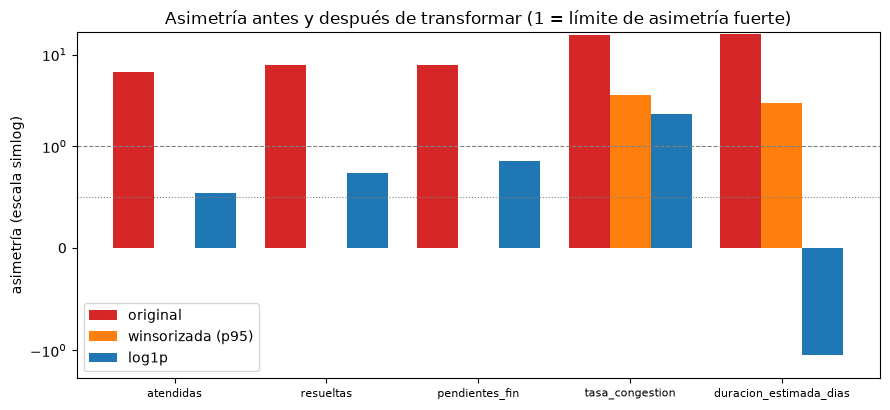

In [3]:
fig, ax = plt.subplots(figsize=(9, 4.2))
pos = np.arange(len(asimetria))
ax.bar(pos - 0.27, asimetria["asimetria_original"], 0.27, label="original", color="tab:red")
ax.bar(pos, asimetria["asimetria_winsorizada"], 0.27, label="winsorizada (p95)", color="tab:orange")
ax.bar(pos + 0.27, asimetria["asimetria_log1p"], 0.27, label="log1p", color="tab:blue")
ax.axhline(1, color="gray", ls="--", lw=0.8)
ax.axhline(0.5, color="gray", ls=":", lw=0.8)
ax.set_yscale("symlog", linthresh=1)
ax.set_xticks(pos)
ax.set_xticklabels(asimetria["variable"], fontsize=8)
ax.set_ylabel("asimetría (escala simlog)")
ax.set_title("Asimetría antes y después de transformar (1 = límite de asimetría fuerte)")
ax.legend()
plt.tight_layout()
plt.show()

## 2. Discretizar: `pd.cut` con umbrales de negocio y `pd.qcut` con cuantiles
Dos formas de la clase. **`cut`** con las bandas del CEJA (tasa de resolución: menor que 0,90 crítica, de 0,90 a 0,99 mejorable, 1 o más óptima), que
son umbrales fijados por una fuente externa. **`qcut`** en terciles de duración estimada, que reparten la misma cantidad de procesos en cada grupo.
Luego se cruza con la materia y se calcula el **índice contra la base** (1,0 = lo esperado si la materia no importara).

In [4]:
base = proc[proc["tasa_resolucion"].notna() & proc["duracion_estimada_dias"].notna()].copy()
base["banda_resolucion"] = pd.cut(base["tasa_resolucion"].astype(float), bins=[-np.inf, 0.90, 1.0 - 1e-9, np.inf],
                                  labels=["crítica (< 0,90)", "mejorable (0,90 a 0,99)", "óptima (≥ 1,00)"])
base["tercil_duracion"] = pd.qcut(base["duracion_estimada_dias"].astype(float), 3, labels=["corta", "media", "larga"], duplicates="drop")
print("n =", len(base), "| terciles de duración (días):", [round(x) for x in pd.qcut(base["duracion_estimada_dias"].astype(float), 3, retbins=True, duplicates="drop")[1]])

def indice(col):
    cruce = pd.crosstab(base["materia_homologada"], base[col], normalize="index")
    peso = base[col].value_counts(normalize=True)
    return (cruce / peso).round(2), cruce, peso

idx_b, cruce_b, peso_b = indice("banda_resolucion")
idx_t, cruce_t, peso_t = indice("tercil_duracion")
salida = pd.concat([cruce_b.add_prefix("pct_").round(3), idx_b.add_prefix("indice_"), cruce_t.add_prefix("pct_duracion_").round(3), idx_t.add_prefix("indice_duracion_")], axis=1)
salida.insert(0, "n_procesos", base["materia_homologada"].value_counts())
salida.to_csv(OUT_EDA / "segmentos_materia.csv", encoding="utf-8")
assert abs(peso_b.sum() - 1) < 1e-9 and abs(peso_t.sum() - 1) < 1e-9
print("Participación de cada banda en la base:\n", peso_b.round(3).to_string())
idx_b

n = 1082 | terciles de duración (días): [0, 120, 365, 29200]
Participación de cada banda en la base:
 banda_resolucion
óptima (≥ 1,00)            0.500
crítica (< 0,90)           0.377
mejorable (0,90 a 0,99)    0.123


banda_resolucion,"crítica (< 0,90)","mejorable (0,90 a 0,99)","óptima (≥ 1,00)"
materia_homologada,,,
Partido Administrativo Coactivo Fiscal y Tributario,1.04,0.29,1.14
Partido de Trabajo y Seguridad Social,0.96,0.59,1.13
Público Civil y Comercial,1.15,1.22,0.83
Público Niñez y Adolescencia,0.98,0.75,1.08
Público de Familia,0.86,1.20,1.06


In [5]:
idx_t

tercil_duracion,corta,media,larga
materia_homologada,,,
Partido Administrativo Coactivo Fiscal y Tributario,0.96,0.19,2.06
Partido de Trabajo y Seguridad Social,0.58,0.82,1.70
Público Civil y Comercial,0.82,1.10,1.08
Público Niñez y Adolescencia,1.50,0.69,0.83
Público de Familia,0.93,1.30,0.70


## 3. Contexto de grupo: `groupby().transform` y `merge` con `suffixes`
«Agrupaciones y segmentaciones» de la clase: calcular un estadístico por grupo y **devolverlo a cada fila**. Aquí, la duración de cada proceso se compara con la
**mediana de su materia y ámbito**, para distinguir un proceso lento *en su contexto* de uno que es lento porque toda su materia lo es.
Se escribe en un archivo nuevo; la capa curada no se toca.

In [6]:
ctx = proc[proc["duracion_estimada_dias"].notna()][["ambito", "entidad", "materia_homologada", "tipo_proceso", "atendidas", "pendientes_fin", "duracion_estimada_dias"]].copy()
ctx["mediana_materia_ambito"] = ctx.groupby(["materia_homologada", "ambito"])["duracion_estimada_dias"].transform("median")
ctx["razon_vs_mediana"] = np.where(ctx["mediana_materia_ambito"] > 0, ctx["duracion_estimada_dias"] / ctx["mediana_materia_ambito"], np.nan)
# La misma idea con merge: traer a cada fila el promedio de su departamento-materia con sufijos explícitos.
resumen = ctx.groupby(["materia_homologada", "ambito"], as_index=False).agg(duracion_media=("duracion_estimada_dias", "mean"), n=("duracion_estimada_dias", "size"))
unido = ctx.merge(resumen, on=["materia_homologada", "ambito"], how="left", suffixes=("", "_grupo"), validate="m:1")
assert len(unido) == len(ctx) and unido["n"].notna().all()
assert np.allclose(unido["mediana_materia_ambito"], ctx["mediana_materia_ambito"])
ctx.sort_values("razon_vs_mediana", ascending=False).to_csv(OUT_EDA / "contexto_grupo_procesos.csv", index=False, encoding="utf-8")
grandes = ctx[ctx["atendidas"] >= 100].sort_values("razon_vs_mediana", ascending=False)
print(len(ctx), "procesos con duración;", int((ctx["razon_vs_mediana"] > 3).sum()), "tardan más de 3 veces la mediana de su materia y ámbito")
print("entre los de 100 o más causas atendidas:", int((grandes["razon_vs_mediana"] > 3).sum()), "de", len(grandes))
grandes.head(8)[["entidad", "ambito", "materia_homologada", "tipo_proceso", "atendidas", "duracion_estimada_dias", "mediana_materia_ambito", "razon_vs_mediana"]].round(1)

1122 procesos con duración; 198 tardan más de 3 veces la mediana de su materia y ámbito
entre los de 100 o más causas atendidas: 53 de 360


,entidad,ambito,materia_homologada,tipo_proceso,atendidas,duracion_estimada_dias,mediana_materia_ambito,razon_vs_mediana
856,LA PAZ,capital,Público Niñez y Adolescencia,OTROS CON PROCEDIMIENTO ESPECIAL,144,5475.0,94.2,58.1
860,EL ALTO,capital,Público Niñez y Adolescencia,"INFRACCIONES POR VIOLENCIA CONTRA NIÑAS, NIÑOS...",240,3004.2,94.2,31.9
1814,BENI,provincia,Partido de Trabajo y Seguridad Social,INFRACCION A LEYES SOCIALES,216,5266.4,412.3,12.8
1437,SANTA CRUZ,provincia,Público Civil y Comercial,OTROS MONITORIOS,226,2479.5,201.1,12.3
499,LA PAZ,capital,Partido de Trabajo y Seguridad Social,COACTIVO SOCIAL AFPs,2185,4354.1,358.6,12.1
835,LA PAZ,capital,Público Niñez y Adolescencia,"INFRACCIONES POR VIOLENCIA CONTRA NIÑAS, NIÑOS...",338,844.5,94.2,9.0
433,SANTA CRUZ,capital,Público de Familia,PROCESOS INNOMINADOS - OTROS,523,1212.6,165.7,7.3
1077,POTOSI,capital,Partido Administrativo Coactivo Fiscal y Tribu...,COACTIVO FISCAL,568,4242.1,582.5,7.3


## 4. Variables temporales sobre la serie 2007-2023
«Generación de variables basadas en el tiempo»: `shift` (rezago), `pct_change` (variación interanual) y `rolling` (media móvil). La serie es anual, así que
**no aplica** la codificación cíclica seno/coseno (sirve para hora, día de la semana o mes). Se usa el total nacional del notebook 15.

In [7]:
serie = pd.read_csv(OUT_EDA / "serie_historica_indicadores.csv")
nac = serie[serie["ambito"] == "nacional"].sort_values("gestion").set_index("gestion")
t = pd.DataFrame(index=nac.index)
for col in ["ingresadas", "resueltas", "pendientes_fin"]:
    t[col] = nac[col]
    t["var_interanual_" + col] = nac[col].pct_change() * 100
t["tasa_resolucion"] = nac["tasa_resolucion"]
t["tasa_resolucion_rezago_1"] = nac["tasa_resolucion"].shift(1)
t["tasa_resolucion_media_movil_3"] = nac["tasa_resolucion"].rolling(3).mean()
t["tasa_congestion"] = nac["tasa_congestion"]
t["tasa_congestion_media_movil_3"] = nac["tasa_congestion"].rolling(3).mean()
t["salto_ingresadas"] = t["var_interanual_ingresadas"].abs() > 15
t.round(3).to_csv(OUT_EDA / "serie_variables_temporales.csv", encoding="utf-8")
ac = float(t["tasa_resolucion"].autocorr(lag=1))
saltos = [int(a) for a in t.index[t["salto_ingresadas"]]]
assert 2020 in saltos and 2021 in saltos
print("años con variación interanual de ingresadas de más de 15 % (en valor absoluto):", saltos)
print("autocorrelación de la tasa de resolución con su rezago de 1 año: {:.2f}".format(ac))
print("autocorrelación de la tasa de resolución solo desde 2015: {:.2f}".format(float(t.loc[2015:, "tasa_resolucion"].autocorr(lag=1))))
t.loc[2018:, ["var_interanual_ingresadas", "var_interanual_resueltas", "var_interanual_pendientes_fin", "tasa_resolucion", "tasa_resolucion_media_movil_3", "tasa_congestion_media_movil_3"]].round(2)

años con variación interanual de ingresadas de más de 15 % (en valor absoluto): [2013, 2016, 2020, 2021]
autocorrelación de la tasa de resolución con su rezago de 1 año: 0.80
autocorrelación de la tasa de resolución solo desde 2015: -0.17


,var_interanual_ingresadas,var_interanual_resueltas,var_interanual_pendientes_fin,tasa_resolucion,tasa_resolucion_media_movil_3,tasa_congestion_media_movil_3
gestion,,,,,,
2018,-5.80,-2.15,-10.27,1.00,1.01,2.03
2019,3.58,-3.07,6.66,0.93,0.96,2.03
2020,-27.08,-22.33,-2.89,0.99,0.97,2.12
2021,32.86,27.33,-1.00,0.95,0.96,2.14
2022,8.03,5.39,5.97,0.93,0.96,2.13
2023,6.18,8.86,-2.24,0.95,0.94,2.00


## 5. Correlación entre indicadores (sin eliminar nada)
La clase advierte dos cosas: **correlación no es causalidad**, y una correlación alta **no justifica borrar una columna** automáticamente. En este proyecto hay
una razón extra: varias columnas están ligadas por **identidades contables** (`atendidas = resueltas + pendientes_fin`), así que una |r| alta es esperada y no
informa. Se calcula, se lista lo que pasa de 0,90 y se marca cuáles son pares de identidad; no se elimina ninguna columna.

In [8]:
cols = ["log_atendidas", "log_nuevas_ingresadas", "log_resueltas", "log_pendientes_fin", "tasa_resolucion", "tasa_congestion_winsorizada", "duracion_estimada_winsorizada", "tasa_pendencia"]
datos = proc[cols].astype(float)
datos["tasa_resolucion"] = datos["tasa_resolucion"].clip(upper=3)
pear = datos.corr(method="pearson")
spear = datos.corr(method="spearman")
contables = {"log_atendidas", "log_nuevas_ingresadas", "log_resueltas", "log_pendientes_fin"}
pares = []
for i, a in enumerate(cols):
    for b in cols[i + 1:]:
        pares.append({"variable_a": a, "variable_b": b, "pearson": pear.loc[a, b], "spearman": spear.loc[a, b],
                      "|r| > 0,90": abs(pear.loc[a, b]) > 0.9 or abs(spear.loc[a, b]) > 0.9,
                      "ambas_son_cantidades_contables": a in contables and b in contables})
pares = pd.DataFrame(pares)
pares.to_csv(OUT_EDA / "correlaciones_indicadores.csv", index=False, encoding="utf-8")
altas = pares[pares["|r| > 0,90"]]
print(len(altas), "de", len(pares), "pares pasan de 0,90;", int(altas["ambas_son_cantidades_contables"].sum()), "son cantidades ligadas por identidades contables.")
print("No se elimina ninguna columna: la capa curada conserva sus", curado.shape[1], "columnas.")
altas.round(3)

7 de 28 pares pasan de 0,90; 4 son cantidades ligadas por identidades contables.
No se elimina ninguna columna: la capa curada conserva sus 118 columnas.


,variable_a,variable_b,pearson,spearman,"|r| > 0,90",ambas_son_cantidades_contables
0,log_atendidas,log_nuevas_ingresadas,0.975,0.968,True,True
1,log_atendidas,log_resueltas,0.972,0.964,True,True
2,log_atendidas,log_pendientes_fin,0.938,0.930,True,True
7,log_nuevas_ingresadas,log_resueltas,0.974,0.960,True,True
25,tasa_congestion_winsorizada,duracion_estimada_winsorizada,0.950,0.995,True,False
26,tasa_congestion_winsorizada,tasa_pendencia,0.766,0.995,True,False
27,duracion_estimada_winsorizada,tasa_pendencia,0.824,0.999,True,False


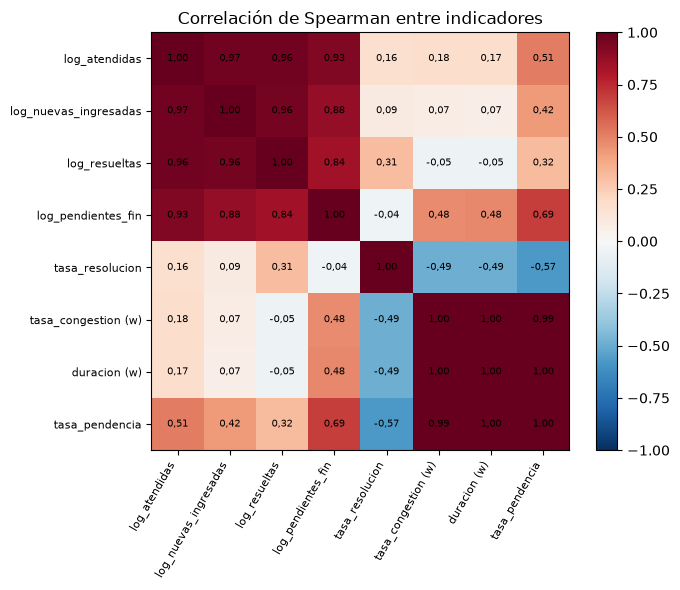

In [9]:
fig, ax = plt.subplots(figsize=(7.2, 6))
im = ax.imshow(spear.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(cols)))
ax.set_yticks(range(len(cols)))
ax.set_xticklabels([c.replace("_estimada", "").replace("_winsorizada", " (w)") for c in cols], rotation=60, ha="right", fontsize=8)
ax.set_yticklabels([c.replace("_estimada", "").replace("_winsorizada", " (w)") for c in cols], fontsize=8)
for i in range(len(cols)):
    for j in range(len(cols)):
        ax.text(j, i, "{:.2f}".format(spear.values[i, j]).replace(".", ","), ha="center", va="center", fontsize=7)
plt.colorbar(im, fraction=0.04)
ax.set_title("Correlación de Spearman entre indicadores")
plt.tight_layout()
plt.show()

## 6. PCA con estandarización
Las mismas cuatro variables del agrupamiento del notebook 16 (volumen en `log1p`, tasa de resolución cortada en 3, duración en `log1p` y tasa de pendencia),
**estandarizadas** (la clase: PCA es sensible a la escala) y sin valores vacíos. Se calcula con la descomposición en valores singulares de `numpy` y se verifica que
la varianza explicada suma 100 % y que los componentes son ortogonales. Sirve para **visualizar** y para saber cuántas dimensiones reales hay.

In [10]:
q = proc[proc["duracion_estimada_dias"].notna() & proc["tasa_resolucion"].notna()].copy()
F = pd.DataFrame({"volumen": np.log1p(q["atendidas"].astype(float)), "tasa_resolucion": q["tasa_resolucion"].astype(float).clip(upper=3),
                  "duracion": np.log1p(q["duracion_estimada_dias"].astype(float)), "pendencia": q["tasa_pendencia"].astype(float)})
Z = ((F - F.mean()) / F.std()).to_numpy(dtype=float)
U, S, Vt = np.linalg.svd(Z, full_matrices=False)
varianza = S ** 2 / (len(Z) - 1)
pct = varianza / varianza.sum() * 100
assert abs(pct.sum() - 100) < 1e-9 and np.allclose(Vt @ Vt.T, np.eye(4), atol=1e-9)
componentes = Z @ Vt.T
pca = pd.DataFrame({"componente": ["PC1", "PC2", "PC3", "PC4"], "varianza_pct": pct, "acumulada_pct": pct.cumsum()})
cargas = pd.DataFrame(Vt.T, index=F.columns, columns=pca["componente"])
pca.to_csv(OUT_EDA / "pca_varianza.csv", index=False, encoding="utf-8")
cargas.round(3).to_csv(OUT_EDA / "pca_cargas.csv", encoding="utf-8")
print("n =", len(Z), "| los 2 primeros componentes explican {:.1f} % y los 3 primeros {:.1f} %".format(pca["acumulada_pct"][1], pca["acumulada_pct"][2]))
cargas.round(2)

n = 1082 | los 2 primeros componentes explican 79.6 % y los 3 primeros 97.8 %


componente,PC1,PC2,PC3,PC4
volumen,-0.23,-0.85,-0.46,0.12
tasa_resolucion,0.37,-0.51,0.78,0.03
duracion,-0.64,-0.08,0.28,-0.71
pendencia,-0.63,0.09,0.33,0.69


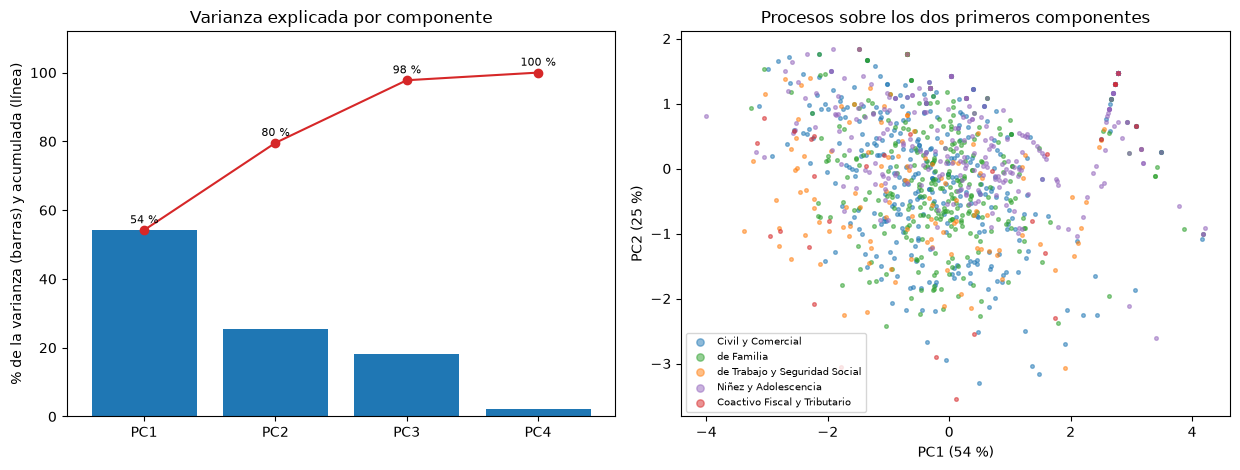

In [11]:
fig, ejes = plt.subplots(1, 2, figsize=(12.5, 4.8))
ejes[0].bar(pca["componente"], pca["varianza_pct"], color="tab:blue")
ejes[0].plot(pca["componente"], pca["acumulada_pct"], color="tab:red", marker="o")
for i, v in enumerate(pca["acumulada_pct"]):
    ejes[0].text(i, v + 2, "{:.0f} %".format(v), ha="center", fontsize=8)
ejes[0].set_ylim(0, 112)
ejes[0].set_ylabel("% de la varianza (barras) y acumulada (línea)")
ejes[0].set_title("Varianza explicada por componente")
colores = {"Público Civil y Comercial": "tab:blue", "Público de Familia": "tab:green", "Partido de Trabajo y Seguridad Social": "tab:orange",
           "Público Niñez y Adolescencia": "tab:purple", "Partido Administrativo Coactivo Fiscal y Tributario": "tab:red"}
for materia, color in colores.items():
    m = (q["materia_homologada"] == materia).to_numpy()
    ejes[1].scatter(componentes[m, 0], componentes[m, 1], s=7, alpha=0.5, color=color, label=materia.replace("Público ", "").replace("Partido ", "").replace("Administrativo ", ""))
ejes[1].set_xlabel("PC1 ({:.0f} %)".format(pca["varianza_pct"][0]))
ejes[1].set_ylabel("PC2 ({:.0f} %)".format(pca["varianza_pct"][1]))
ejes[1].set_title("Procesos sobre los dos primeros componentes")
ejes[1].legend(fontsize=7, markerscale=2)
plt.tight_layout()
plt.show()

## 7. Outliers multivariados: distancia de Mahalanobis
La clase distingue el outlier **univariado** (un valor extremo en una variable, lo que hacen las banderas por estrato del notebook 11) del **multivariado** (una combinación
rara de valores razonables). LOF y DBSCAN, que enseña la clase, necesitan `scikit-learn`, que el proyecto no usa. Se emplea su equivalente clásico: la distancia de Mahalanobis
sobre las variables estandarizadas, que bajo normalidad sigue una chi-cuadrado con 4 grados de libertad (umbral del 99,9 %). Es una **marca**: ninguna fila se elimina.

In [12]:
cov_inv = np.linalg.inv(np.cov(Z, rowvar=False))
d2 = np.einsum("ij,jk,ik->i", Z, cov_inv, Z)
umbral = float(stats.chi2.ppf(0.999, df=4))
q["mahalanobis_d2"] = d2
q["es_outlier_multivariado"] = d2 > umbral
univ = [c for c in q.columns if c.startswith("es_outlier_severo_")]
q["es_outlier_severo_univariado"] = q[univ].fillna(False).astype(bool).any(axis=1)
tabla = pd.crosstab(q["es_outlier_multivariado"], q["es_outlier_severo_univariado"])
multi = q[q["es_outlier_multivariado"]]
solo_multi = multi[~multi["es_outlier_severo_univariado"]]
q[["ambito", "entidad", "materia_homologada", "tipo_proceso", "atendidas", "tasa_resolucion", "duracion_estimada_dias", "tasa_pendencia", "mahalanobis_d2",
   "es_outlier_multivariado", "es_outlier_severo_univariado"]].sort_values("mahalanobis_d2", ascending=False).to_csv(OUT_EDA / "outliers_multivariados.csv", index=False, encoding="utf-8")
assert int(q["es_outlier_multivariado"].sum()) == len(multi) and len(q) == len(Z)
print("umbral chi² (99,9 %, 4 gl): {:.2f} | {} de {} procesos son outliers multivariados ({:.1f} %)".format(umbral, len(multi), len(q), len(multi) / len(q) * 100))
print("de ellos, {} ya tenían una bandera severa univariada y {} solo se ven en conjunto".format(len(multi) - len(solo_multi), len(solo_multi)))
print("las banderas univariadas severas marcan {} procesos de los {}".format(int(q["es_outlier_severo_univariado"].sum()), len(q)))
solo_multi.sort_values("mahalanobis_d2", ascending=False).head(6)[["entidad", "materia_homologada", "tipo_proceso", "atendidas", "tasa_resolucion", "duracion_estimada_dias", "mahalanobis_d2"]].round(1)

umbral chi² (99,9 %, 4 gl): 18.47 | 20 de 1082 procesos son outliers multivariados (1.8 %)
de ellos, 6 ya tenían una bandera severa univariada y 14 solo se ven en conjunto
las banderas univariadas severas marcan 246 procesos de los 1082


,entidad,materia_homologada,tipo_proceso,atendidas,tasa_resolucion,duracion_estimada_dias,mahalanobis_d2
1770,ORURO,Partido de Trabajo y Seguridad Social,COACTIVO SOCIAL AFPs,7,3.0,486.7,24.1
1057,SUCRE,Partido Administrativo Coactivo Fiscal y Tribu...,COACTIVO FISCAL,149,3.0,526.6,23.1
818,SUCRE,Público Niñez y Adolescencia,CONVERSIÓN DE GUARDA EN ADOPCIÓN,3,3.0,0.0,22.1
1755,COCHABAMBA,Partido de Trabajo y Seguridad Social,DESAFUERO SINDICAL,5,3.0,243.3,22.0
734,TARIJA,Público de Familia,NULIDAD DE ACUERDOS EN LA VIA VOLUNTARIA NOTAR...,4,4.0,0.0,22.0
1613,POTOSI,Público Niñez y Adolescencia,CONVERSIÓN DE GUARDA EN ADOPCIÓN,4,4.0,0.0,22.0


## Lectura
- **Asimetría**: `log1p` baja de fuerte a moderada la asimetría de las tres cantidades (atendidas, resueltas, pendientes), pero **no alcanza** en las dos razones: la tasa de congestión sigue con asimetría fuerte y la duración queda con asimetría fuerte *negativa* (el logaritmo corrige de más). La winsorización reduce menos. Es el caso de la regla 5 de la clase: transformar no garantiza mejorar, hay que medirlo.
- **Segmentos**: civil se concentra en la banda crítica (índice 1,15) y es la materia menos óptima (0,83); coactivo (2,06) y trabajo (1,70) se concentran en el tercil de duración larga; niñez en el corto (1,50).
- **Contexto de grupo**: 198 de 1.122 procesos tardan más de tres veces la mediana de su materia y ámbito; con 100 o más causas atendidas son 53 de 360. Separa lo lento por sí mismo de lo lento por el contexto.
- **Serie**: la variación interanual de las ingresadas pasa de 15 % en 2013, 2016, 2020 y 2021; la tasa de resolución, desde 2015, no tiene memoria de un año a otro (autocorrelación −0,17), es decir, oscila alrededor de 1.
- **Correlación**: 7 de 28 pares pasan de 0,90 y 4 son identidades contables; los otros tres son tasa de congestión, duración y pendencia, que miden lo mismo con fórmulas emparentadas. No se elimina ninguna columna.
- **PCA**: dos componentes explican 79,6 % y tres 97,8 %: los cuatro indicadores tienen poco más de tres dimensiones reales. El primer componente es duración y pendencia contra tasa de resolución; el segundo, volumen.
- **Multivariados**: 20 procesos (1,8 %) son raros en conjunto; 14 no tienen ninguna bandera univariada severa. Son filas pequeñas con tasa de resolución cortada en 3 y sin pendientes: combinaciones atípicas, no errores. Mahalanobis supone normalidad que estos datos no cumplen, así que es una **marca para revisar**, no una conclusión.